In [4]:
!pip install plotly
!pip install missingno


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# EDA

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

import missingno as msno

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import precision_score, confusion_matrix
from sklearn import tree
df= pd.read_csv('water_potability.csv')

In [8]:
describe = df.describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [13]:
# dependent variable analysis
d = pd.DataFrame(df['Potability'].value_counts())

fig = px.pie(
    d, 
    values='count', 
    names=["Not Potable", "Potable"], 
    hole=0.35, 
    opacity=0.8, 
    labels={"count": "Number of Samples"}
)
fig.update_layout(title=dict(text="Pie Chart of Potability", x=0.5, y=0.9, font=dict(size=20)))
fig.update_traces(textposition="outside", textinfo="percent+label")
fig.show()
fig.write_html("potability_pie_chart.html")

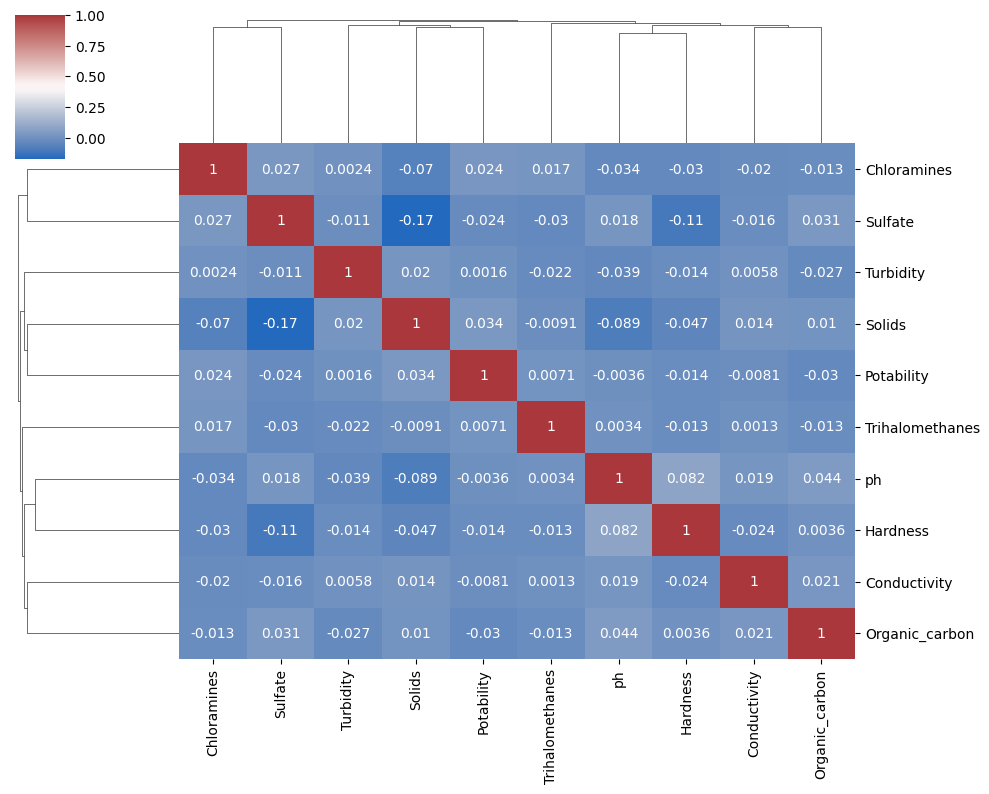

In [16]:
# Corelation Analysis
sns.clustermap(df.corr(), annot=True, cmap='vlag', figsize=(10, 8))
plt.show()

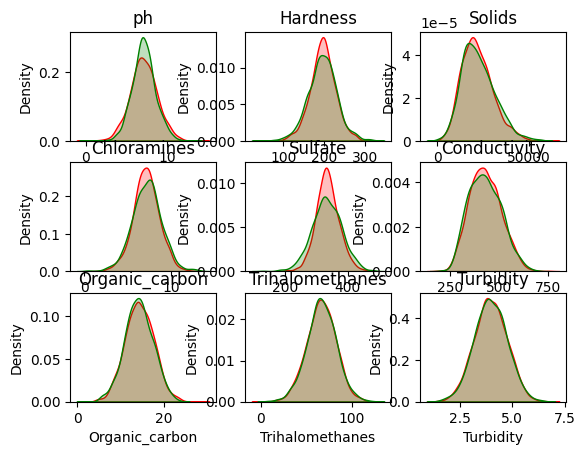

In [17]:
# distribution of features

non_potable = df[df['Potability'] == 0]
potable = df[df['Potability'] == 1]
plt.figure()
for ax , col in enumerate(df.columns[:-1]):
    plt.subplot(3, 3, ax+1)
    sns.kdeplot(non_potable[col], label='Not Potable', color='red', fill=True)
    sns.kdeplot(potable[col], label='Potable', color='green', fill=True)
    plt.title(col)

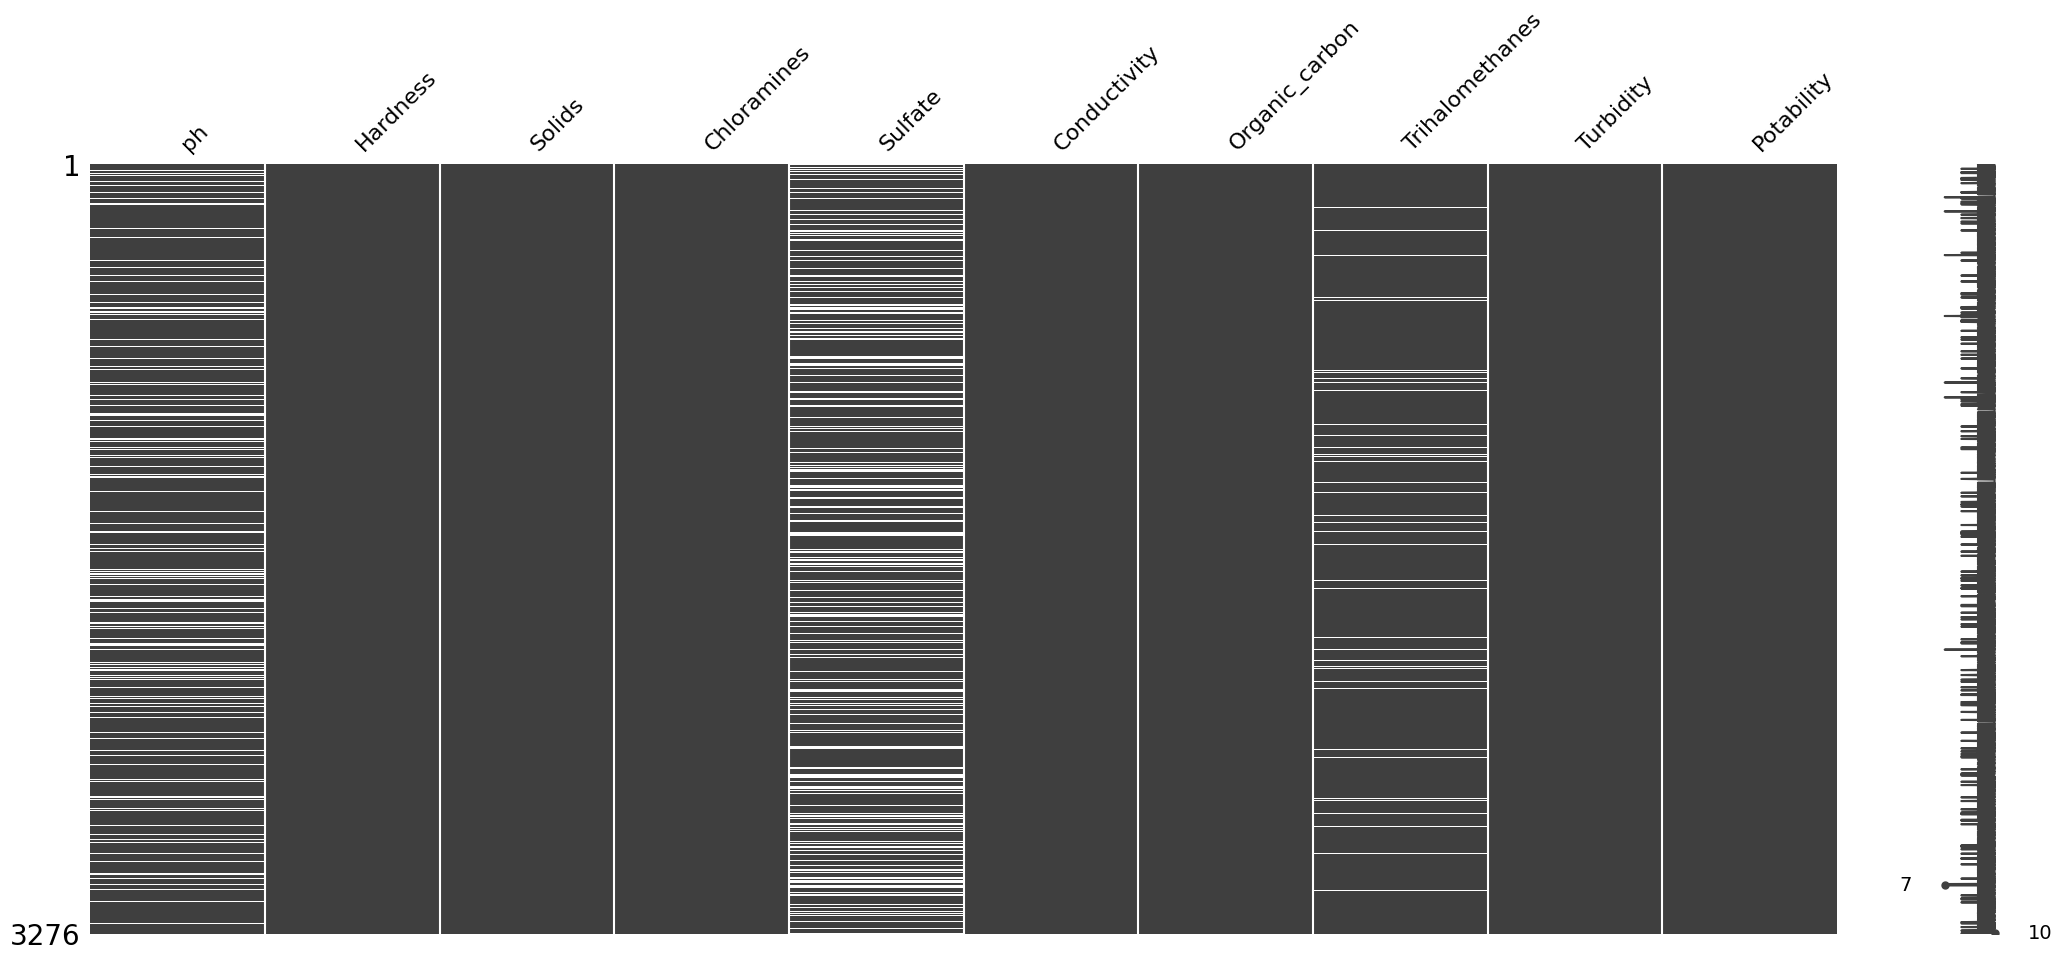

In [18]:
# missing values analysis
msno.matrix(df)
plt.show()

In [21]:
# PREPROCESSING
print(df.isnull().sum())
df['ph'].fillna(df['ph'].mean(), inplace=True)
df['Sulfate'].fillna(df['Sulfate'].mean(), inplace=True)
df['Trihalomethanes'].fillna(df['Trihalomethanes'].mean(), inplace=True)

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


C:\Users\kerim\AppData\Local\Temp\ipykernel_13548\4235866014.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['ph'].fillna(df['ph'].mean(), inplace=True)
C:\Users\kerim\AppData\Local\Temp\ipykernel_13548\4235866014.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For examp

In [ ]:
X = df.drop('Potability', axis=1).values
y = df['Potability'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_max = numpy.max(X_train)
X_train_min = numpy.min(X_train)
X_train_scaled = (X_train - X_train_min) / (X_train_max - X_train_min)
X_test_scaled = (X_test - X_train_min) / (X_train_max - X_train_min)

NameError: name 'numpy' is not defined